# Лабораторная работа 4
> - **Предмет:** МОСИИ
> - **Студент:** Руденко Андрей Артемович
> - **Группа:** М9125-01.04.02МКТ

**Цель работы:** Улучшение свёрточной нейросети для классификации чистых и грязных тарелок.

In [1]:
import numpy as np
import pandas as pd
import os
import zipfile
import shutil

import torch
import torchvision
import matplotlib.pyplot as plt
import time
import copy

from torchvision import transforms, models

## Данные

In [2]:
with zipfile.ZipFile('plates.zip', 'r') as zip_obj:
    zip_obj.extractall('.')

data_root = 'plates'
print(os.listdir(data_root))

['.DS_Store', 'test', 'train']


In [3]:
train_dir = 'train'
val_dir = 'val'

class_names = ['cleaned', 'dirty']

for dir_name in [train_dir, val_dir]:
    for class_name in class_names:
        os.makedirs(os.path.join(dir_name, class_name), exist_ok=True)

for class_name in class_names:
    source_dir = os.path.join(data_root, 'train', class_name)
    for i, file_name in enumerate(sorted(os.listdir(source_dir))):
        if i % 6 != 0:
            dest_dir = os.path.join(train_dir, class_name)
        else:
            dest_dir = os.path.join(val_dir, class_name)
        shutil.copy(os.path.join(source_dir, file_name), os.path.join(dest_dir, file_name))

In [4]:
train_transforms = transforms.Compose([
    transforms.RandomResizedCrop(224),
    transforms.RandomHorizontalFlip(),
    transforms.ToTensor(),
    transforms.Normalize([0.485, 0.456, 0.406], [0.229, 0.224, 0.225])
])

val_transforms = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.ToTensor(),
    transforms.Normalize([0.485, 0.456, 0.406], [0.229, 0.224, 0.225])
])

train_dataset = torchvision.datasets.ImageFolder(train_dir, train_transforms)
val_dataset = torchvision.datasets.ImageFolder(val_dir, val_transforms)

batch_size = 8
train_dataloader = torch.utils.data.DataLoader(
    train_dataset, batch_size=batch_size, shuffle=True, num_workers=0)
val_dataloader = torch.utils.data.DataLoader(
    val_dataset, batch_size=batch_size, shuffle=False, num_workers=0)

In [5]:
len(train_dataloader), len(train_dataset)

(5, 34)

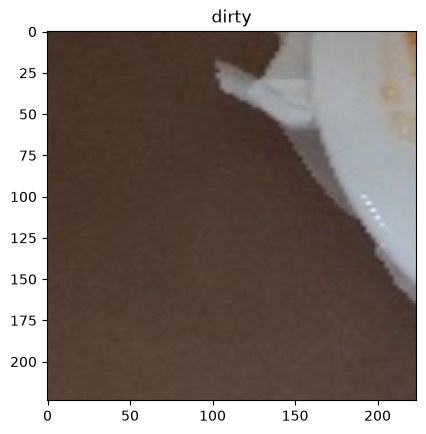

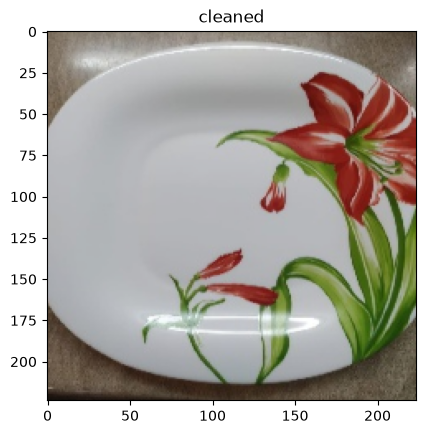

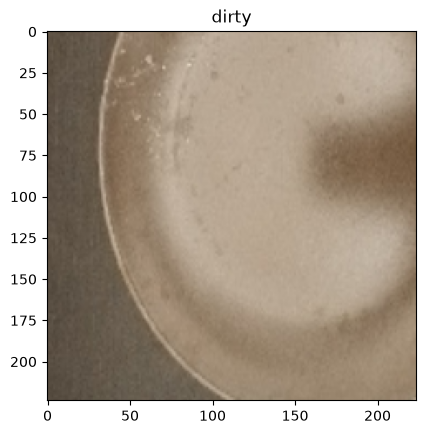

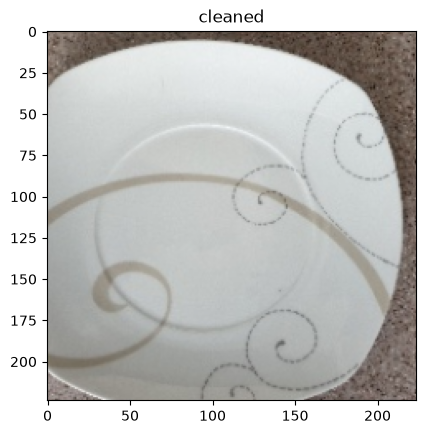

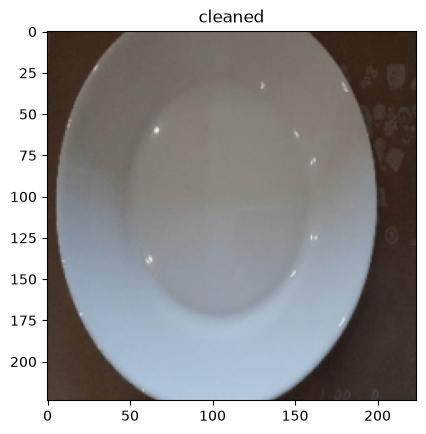

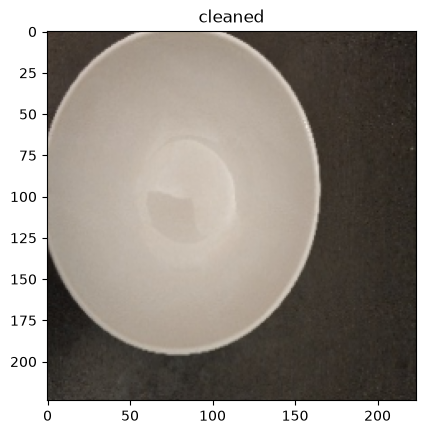

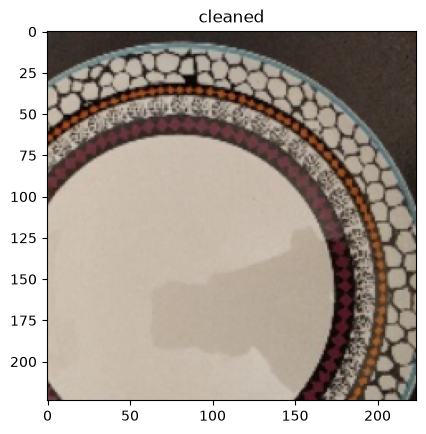

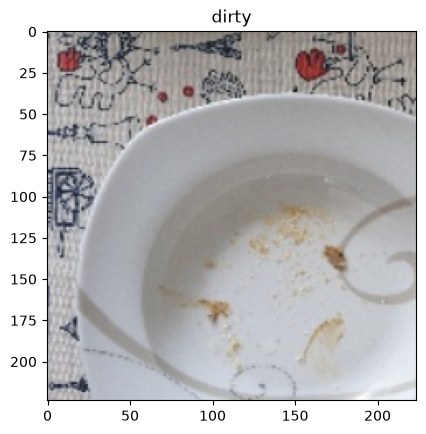

In [6]:
mean = np.array([0.485, 0.456, 0.406])
std = np.array([0.229, 0.224, 0.225])

def show_input(input_tensor, title=''):
    image = input_tensor.permute(1, 2, 0).numpy()
    image = std * image + mean
    plt.imshow(image.clip(0, 1))
    plt.title(title)
    plt.show()
    plt.pause(0.001)

X_batch, y_batch = next(iter(train_dataloader))

for x_item, y_item in zip(X_batch, y_batch):
    show_input(x_item, title=class_names[y_item])

## Baseline

In [7]:
def train_model(model, loss, optimizer, scheduler, num_epochs):
    for epoch in range(num_epochs):
        print('Epoch {}/{}:'.format(epoch, num_epochs - 1), flush=True)

        # Each epoch has a training and validation phase
        for phase in ['train', 'val']:
            if phase == 'train':
                dataloader = train_dataloader
                scheduler.step()
                model.train()  # Set model to training mode
            else:
                dataloader = val_dataloader
                model.eval()   # Set model to evaluate mode

            running_loss = 0.
            running_acc = 0.

            # Iterate over data.
            for inputs, labels in dataloader:
                inputs = inputs.to(device)
                labels = labels.to(device)

                optimizer.zero_grad()

                # forward and backward
                with torch.set_grad_enabled(phase == 'train'):
                    preds = model(inputs)
                    loss_value = loss(preds, labels)
                    preds_class = preds.argmax(dim=1)

                    # backward + optimize only if in training phase
                    if phase == 'train':
                        loss_value.backward()
                        optimizer.step()

                # statistics
                running_loss += loss_value.item()
                running_acc += (preds_class == labels.data).float().mean()

            epoch_loss = running_loss / len(dataloader)
            epoch_acc = running_acc / len(dataloader)

            print('{} Loss: {:.4f} Acc: {:.4f}'.format(phase, epoch_loss, epoch_acc), flush=True)

    return model

In [8]:
torch.manual_seed(42)

model = models.resnet18(weights=models.ResNet18_Weights.IMAGENET1K_V1)

# Disable grad for all conv layers
for param in model.parameters():
    param.requires_grad = False

model.fc = torch.nn.Linear(model.fc.in_features, 2)

device = torch.device("cuda:0" if torch.cuda.is_available() else "cpu")
model = model.to(device)

loss = torch.nn.CrossEntropyLoss()
optimizer = torch.optim.Adam(model.parameters(), lr=1.0e-3)

# Decay LR by a factor of 0.1 every 7 epochs
scheduler = torch.optim.lr_scheduler.StepLR(optimizer, step_size=7, gamma=0.1)

In [9]:
train_model(model, loss, optimizer, scheduler, num_epochs=10);

Epoch 0/9:


/tmp/ipykernel_45620/310225256.py:9: UserWarning: Detected call of `lr_scheduler.step()` before `optimizer.step()`. In PyTorch 1.1.0 and later, you should call them in the opposite order: `optimizer.step()` before `lr_scheduler.step()`.  Failure to do this will result in PyTorch skipping the first value of the learning rate schedule. See more details at https://pytorch.org/docs/stable/optim.html#how-to-adjust-learning-rate
  scheduler.step()


train Loss: 0.7865 Acc: 0.3500
val Loss: 0.7119 Acc: 0.6667
Epoch 1/9:
train Loss: 0.6974 Acc: 0.5500
val Loss: 0.6471 Acc: 0.6667
Epoch 2/9:
train Loss: 0.6561 Acc: 0.6000
val Loss: 0.6663 Acc: 0.5000
Epoch 3/9:
train Loss: 0.5689 Acc: 0.7750
val Loss: 0.5667 Acc: 0.6667
Epoch 4/9:
train Loss: 0.6556 Acc: 0.5750
val Loss: 0.5429 Acc: 0.8333
Epoch 5/9:
train Loss: 0.6102 Acc: 0.6500
val Loss: 0.5875 Acc: 0.5000
Epoch 6/9:
train Loss: 0.5547 Acc: 0.6500
val Loss: 0.5929 Acc: 0.6667
Epoch 7/9:
train Loss: 0.5458 Acc: 0.7250
val Loss: 0.5812 Acc: 0.6667
Epoch 8/9:
train Loss: 0.4544 Acc: 0.7750
val Loss: 0.5795 Acc: 0.6667
Epoch 9/9:
train Loss: 0.4893 Acc: 0.7250
val Loss: 0.5579 Acc: 0.6667


## Предсказание для теста

In [10]:
test_dir = 'test'

class ImageFolderWithPaths(torchvision.datasets.ImageFolder):
    def __getitem__(self, index):
        original_tuple = super(ImageFolderWithPaths, self).__getitem__(index)
        path = self.imgs[index][0]
        tuple_with_path = (original_tuple + (path,))
        return tuple_with_path

if not os.path.exists(test_dir):
    shutil.copytree(os.path.join(data_root, 'test'), os.path.join(test_dir, 'unknown'))
test_dataset = ImageFolderWithPaths(test_dir, val_transforms)

test_dataloader = torch.utils.data.DataLoader(
    test_dataset, batch_size=batch_size, shuffle=False, num_workers=0)

In [11]:
model.eval()

test_predictions = []
test_img_paths = []
for inputs, labels, paths in test_dataloader:
    inputs = inputs.to(device)
    labels = labels.to(device)
    with torch.set_grad_enabled(False):
        preds = model(inputs)
    test_predictions.append(
        torch.nn.functional.softmax(preds, dim=1)[:,1].data.cpu().numpy())
    test_img_paths.extend(paths)

test_predictions = np.concatenate(test_predictions)

In [12]:
submission_df = pd.DataFrame.from_dict({'id': test_img_paths, 'label': test_predictions})
submission_df['label'] = submission_df['label'].map(lambda pred: 'dirty' if pred > 0.5 else 'cleaned')
submission_df['id'] = submission_df['id'].map(lambda path: os.path.splitext(os.path.basename(path))[0])
submission_df.set_index('id', inplace=True)
submission_df.head(n=6)

,label
id,
0000,dirty
0001,dirty
0002,dirty
0003,dirty
0004,dirty
0005,dirty


In [13]:
submission_df.to_csv('submission_baseline.csv')

## Вывод работы baseline

Baseline на Kaggle дал 0.69086, хотя в другом запуске эта же модель показывала 0.77553. Модель одна, разница из-за случайности: обучающих картинок всего 34, и результат сильно зависит от того, какие обрезки попали в обучение. Модель почти все тарелки считает грязными: 664 из 744. Валидация состоит всего из нескольких картинок, accuracy на ней скачет, и судить по ней нельзя, поэтому качество смотрю только на Kaggle. Предупреждение про `lr_scheduler` в выводе обучения: `scheduler.step()` вызывается в начале эпохи, поэтому шаг уменьшается на эпоху раньше. Функцию обучения не менял, она одинаковая во всех вариантах, так что сравнение честное.

## ResNet-18 с дообучением

Что поменял относительно baseline:
- дообучаю последний свёрточный блок `layer4`, а не только последний слой, чтобы сеть подстроилась под тарелки;
- больше аугментаций: тарелка круглая, поэтому её можно поворачивать и отражать по вертикали, плюс меняю яркость и контраст;
- 20 эпох вместо 10 и шаг поменьше (`lr = 3e-4`), так как обучается больше весов.

In [14]:
torch.manual_seed(42)

train_transforms = transforms.Compose([
    transforms.RandomResizedCrop(224, scale=(0.5, 1.0)),
    transforms.RandomHorizontalFlip(),
    transforms.RandomVerticalFlip(),
    transforms.RandomRotation(20),
    transforms.ColorJitter(brightness=0.2, contrast=0.2, saturation=0.2),
    transforms.ToTensor(),
    transforms.Normalize([0.485, 0.456, 0.406], [0.229, 0.224, 0.225])
])
train_dataset = torchvision.datasets.ImageFolder(train_dir, train_transforms)
train_dataloader = torch.utils.data.DataLoader(
    train_dataset, batch_size=batch_size, shuffle=True, num_workers=0)

model = models.resnet18(weights=models.ResNet18_Weights.IMAGENET1K_V1)
for param in model.parameters():
    param.requires_grad = False
for param in model.layer4.parameters():
    param.requires_grad = True
model.fc = torch.nn.Linear(model.fc.in_features, 2)
model = model.to(device)

loss = torch.nn.CrossEntropyLoss()
optimizer = torch.optim.Adam([p for p in model.parameters() if p.requires_grad], lr=3.0e-4)
scheduler = torch.optim.lr_scheduler.StepLR(optimizer, step_size=10, gamma=0.1)

train_model(model, loss, optimizer, scheduler, num_epochs=20);

Epoch 0/19:


/tmp/ipykernel_45620/310225256.py:9: UserWarning: Detected call of `lr_scheduler.step()` before `optimizer.step()`. In PyTorch 1.1.0 and later, you should call them in the opposite order: `optimizer.step()` before `lr_scheduler.step()`.  Failure to do this will result in PyTorch skipping the first value of the learning rate schedule. See more details at https://pytorch.org/docs/stable/optim.html#how-to-adjust-learning-rate
  scheduler.step()


train Loss: 0.5586 Acc: 0.7000
val Loss: 0.6182 Acc: 0.8333
Epoch 1/19:
train Loss: 0.4552 Acc: 0.7500
val Loss: 0.6576 Acc: 0.8333
Epoch 2/19:
train Loss: 0.1965 Acc: 0.9250
val Loss: 1.1745 Acc: 0.6667
Epoch 3/19:
train Loss: 0.5837 Acc: 0.8500
val Loss: 1.3346 Acc: 0.6667
Epoch 4/19:
train Loss: 0.4474 Acc: 0.7250
val Loss: 1.5824 Acc: 0.6667
Epoch 5/19:
train Loss: 0.3995 Acc: 0.7000
val Loss: 1.0848 Acc: 0.6667
Epoch 6/19:
train Loss: 0.0947 Acc: 1.0000
val Loss: 0.5248 Acc: 0.6667
Epoch 7/19:
train Loss: 0.3679 Acc: 0.8250
val Loss: 0.4547 Acc: 0.8333
Epoch 8/19:
train Loss: 0.1418 Acc: 0.9750
val Loss: 0.3317 Acc: 0.6667
Epoch 9/19:
train Loss: 0.3022 Acc: 0.9000
val Loss: 0.3556 Acc: 0.6667
Epoch 10/19:
train Loss: 0.2425 Acc: 0.9000
val Loss: 0.3962 Acc: 0.6667
Epoch 11/19:
train Loss: 0.4041 Acc: 0.8250
val Loss: 0.4613 Acc: 0.6667
Epoch 12/19:
train Loss: 0.0327 Acc: 1.0000
val Loss: 0.4234 Acc: 0.6667
Epoch 13/19:
train Loss: 0.5641 Acc: 0.8500
val Loss: 0.4249 Acc: 0.6667


Предсказание для теста делаю так же, как в baseline, поэтому вынес его в функцию.

In [15]:
def make_submission(model, file_name):
    model.eval()
    test_predictions = []
    test_img_paths = []
    for inputs, labels, paths in test_dataloader:
        inputs = inputs.to(device)
        with torch.no_grad():
            preds = model(inputs)
        test_predictions.append(torch.nn.functional.softmax(preds, dim=1)[:, 1].cpu().numpy())
        test_img_paths.extend(paths)

    submission_df = pd.DataFrame({'id': test_img_paths, 'label': np.concatenate(test_predictions)})
    submission_df['label'] = submission_df['label'].map(lambda pred: 'dirty' if pred > 0.5 else 'cleaned')
    submission_df['id'] = submission_df['id'].map(lambda path: os.path.splitext(os.path.basename(path))[0])
    submission_df.set_index('id', inplace=True)
    submission_df.to_csv(file_name)
    print(submission_df['label'].value_counts())


make_submission(model, 'submission_resnet18.csv')

label
dirty      579
cleaned    165
Name: count, dtype: int64


## Вывод работы ResNet-18 с дообучением

На Kaggle 0.83467: выше 0.77 и выше обоих результатов baseline (0.77553 и 0.69086). Дообучение последнего блока помогло сети подстроиться под тарелки, а повороты и отражения дали больше разных картинок из всего 34 обучающих. Модель теперь чаще находит чистые тарелки: 165 против 80 у baseline.

## ResNet-50 с дообучением

То же самое, что в прошлом варианте, но на более глубокой сети ResNet-50.

In [16]:
torch.manual_seed(42)
train_dataloader = torch.utils.data.DataLoader(
    train_dataset, batch_size=batch_size, shuffle=True, num_workers=0)

model = models.resnet50(weights=models.ResNet50_Weights.IMAGENET1K_V2)
for param in model.parameters():
    param.requires_grad = False
for param in model.layer4.parameters():
    param.requires_grad = True
model.fc = torch.nn.Linear(model.fc.in_features, 2)
model = model.to(device)

loss = torch.nn.CrossEntropyLoss()
optimizer = torch.optim.Adam([p for p in model.parameters() if p.requires_grad], lr=3.0e-4)
scheduler = torch.optim.lr_scheduler.StepLR(optimizer, step_size=10, gamma=0.1)

train_model(model, loss, optimizer, scheduler, num_epochs=20);
make_submission(model, 'submission_resnet50.csv')

Epoch 0/19:


/tmp/ipykernel_45620/310225256.py:9: UserWarning: Detected call of `lr_scheduler.step()` before `optimizer.step()`. In PyTorch 1.1.0 and later, you should call them in the opposite order: `optimizer.step()` before `lr_scheduler.step()`.  Failure to do this will result in PyTorch skipping the first value of the learning rate schedule. See more details at https://pytorch.org/docs/stable/optim.html#how-to-adjust-learning-rate
  scheduler.step()


train Loss: 0.7199 Acc: 0.4750
val Loss: 0.7188 Acc: 0.5000
Epoch 1/19:
train Loss: 0.6287 Acc: 0.5250
val Loss: 0.6639 Acc: 0.5000
Epoch 2/19:
train Loss: 0.4926 Acc: 0.8750
val Loss: 0.5991 Acc: 0.6667
Epoch 3/19:
train Loss: 0.3665 Acc: 0.9250
val Loss: 0.5649 Acc: 0.6667
Epoch 4/19:
train Loss: 0.2206 Acc: 0.9500
val Loss: 0.6154 Acc: 0.6667
Epoch 5/19:
train Loss: 0.4032 Acc: 0.8500
val Loss: 0.6044 Acc: 0.6667
Epoch 6/19:
train Loss: 0.2640 Acc: 0.8000
val Loss: 0.6195 Acc: 0.8333
Epoch 7/19:
train Loss: 0.1322 Acc: 1.0000
val Loss: 0.5411 Acc: 0.8333
Epoch 8/19:
train Loss: 0.4056 Acc: 0.9000
val Loss: 0.4924 Acc: 0.8333
Epoch 9/19:
train Loss: 0.1182 Acc: 0.9750
val Loss: 0.4792 Acc: 0.8333
Epoch 10/19:
train Loss: 0.1997 Acc: 0.9000
val Loss: 0.4336 Acc: 0.8333
Epoch 11/19:
train Loss: 0.1213 Acc: 0.9500
val Loss: 0.3982 Acc: 0.8333
Epoch 12/19:
train Loss: 0.1241 Acc: 1.0000
val Loss: 0.3785 Acc: 0.8333
Epoch 13/19:
train Loss: 0.1658 Acc: 1.0000
val Loss: 0.3939 Acc: 0.8333


## Вывод работы ResNet-50 с дообучением

0.73655, хуже ResNet-18, хотя сеть глубже. Скорее всего, для 34 картинок она слишком большая: в её последнем блоке почти вдвое больше весов, и она подстраивается под обучающие картинки, а не учится общему. Как и baseline, она почти все тарелки считает грязными (668 из 744).

## ResNet-50 с усреднением по поворотам

Та же обученная ResNet-50, но каждую тестовую картинку показываю модели 4 раза: как есть, отражённой по горизонтали, по вертикали и повёрнутой на 90°. Вероятности усредняю. Тарелка от этого не меняется, а случайные ошибки модели на одном варианте картинки сглаживаются.

In [17]:
def make_submission_tta(model, file_name):
    model.eval()
    test_predictions = []
    test_img_paths = []
    for inputs, labels, paths in test_dataloader:
        inputs = inputs.to(device)
        with torch.no_grad():
            versions = [inputs, inputs.flip(3), inputs.flip(2), inputs.rot90(1, dims=(2, 3))]
            probs = [torch.nn.functional.softmax(model(x), dim=1)[:, 1] for x in versions]
        test_predictions.append(torch.stack(probs).mean(dim=0).cpu().numpy())
        test_img_paths.extend(paths)

    submission_df = pd.DataFrame({'id': test_img_paths, 'label': np.concatenate(test_predictions)})
    submission_df['label'] = submission_df['label'].map(lambda pred: 'dirty' if pred > 0.5 else 'cleaned')
    submission_df['id'] = submission_df['id'].map(lambda path: os.path.splitext(os.path.basename(path))[0])
    submission_df.set_index('id', inplace=True)
    submission_df.to_csv(file_name)
    print(submission_df['label'].value_counts())


make_submission_tta(model, 'submission_resnet50_tta.csv')

label
dirty      675
cleaned     69
Name: count, dtype: int64


## Вывод работы ResNet-50 с усреднением по поворотам

0.72983, почти как без усреднения. Усреднение сглаживает случайные ошибки, но не исправляет плохо обученную модель: если она ошибается, то на всех четырёх вариантах картинки.

## Технический отчёт

| Модель | Accuracy на Kaggle |
|---|---|
| Baseline, другой запуск | 0.77553 |
| Baseline, мой запуск | 0.69086 |
| **ResNet-18 с дообучением** | **0.83467** |
| ResNet-50 с дообучением | 0.73655 |
| ResNet-50 + усреднение по поворотам | 0.72983 |

Перебить baseline удалось ResNet-18 с дообучением последнего блока, аугментациями и 20 эпохами: 0.83467 против 0.77553 у baseline. Более глубокая ResNet-50 с теми же настройками оказалась хуже: для 34 картинок она, видимо, слишком большая. Усреднение по поворотам на тесте тоже ничего не дало.

Baseline с одной и той же моделью даёт то 0.69, то 0.78, то есть на 34 картинках результат сильно зависит от случайности. Каждый вариант я запускал один раз, поэтому разница между ними частично может быть случайной. Но ResNet-18 оказалась выше обоих запусков baseline, а ResNet-50 ниже лучшего из них.

![](kaggle_score.png)